# Multi-target Chart CNN baseline: horizon × target grid

**Question.** At high frequency, is there any signal in the *direction* of the next move, or only in its *size*?

| | 5 min (h1, reference) | 15 min (h3) | 30 min (h6) | 60 min (h12) |
|---|---|---|---|---|
| `dir` absolute direction: return > 0 (zeros dropped) | `dir_h1` | `dir_h3` | `dir_h6` | `dir_h12` |
| `vol` volatility: \|return\| > stock's training median | `vol_h1` | `vol_h3` | `vol_h6` | `vol_h12` |
| `xsdir` relative direction: return > cross-sectional median | `xsdir_h1` | `xsdir_h3` | `xsdir_h6` | `xsdir_h12` |

- **Input**: one trading day (78 five-minute bars), adjusted point in time to its last bar. Same windows for all 12 cells.
- **Models per cell**: `plain` image CNN (Jiang–Kelly–Xiu style), `series1d` 1D CNN on the raw OHLCV numbers (does the picture help?), HGB on 20 hand features, simple rules. The residual CNN is left out to save GPU time (it tied the plain CNN at 2.6× the cost).
- **Stride 12 for every horizon**: one sample per stock per hour, so a stock's labels never overlap (stride ≥ horizon), and all horizons are scored on the same decision times.
- **Resumable**: each finished cell is saved on Drive and skipped on a rerun; an unfinished CNN resumes from its last epoch.
- **Code**: `chartcnn/` next to this notebook (`chartcnn/grid.py` holds the grid logic).

## 1. Setup

In [1]:
import os, sys, shutil, tempfile
from pathlib import Path

LOCAL_TEST = os.environ.get("CNN78U_LOCAL_NOTEBOOK_TEST") == "1"     # repository QA only
if LOCAL_TEST:
    DEMO = Path(os.environ["CNN78U_LOCAL_DEMO"])
else:
    from google.colab import drive
    drive.mount("/content/drive")
    DEMO = Path("/content/drive/MyDrive/Colab Notebooks/EC/Project/Demo")
HERE = DEMO / "Multi-Target Chart CNN Baseline"   # this notebook, chartcnn/ and runs/
# chartcnn/ is copied into this folder on Drive; in the repository it lives in ../CNN-Relevant.
CODE = HERE if (HERE / "chartcnn").is_dir() else DEMO / "CNN-Relevant"
sys.path.insert(0, str(CODE))

import numpy as np, pandas as pd, torch
from IPython.display import display, Markdown
import chartcnn
from chartcnn import grid
from chartcnn.utils import stage_bundle, save_json
assert chartcnn.__version__ >= "2026-11-14.3", f"stale chartcnn {chartcnn.__version__} in {CODE}"

LOCAL = Path(tempfile.mkdtemp(prefix="mtcnn_", dir=None if LOCAL_TEST else "/content"))
PREPARED = stage_bundle(DEMO, LOCAL / "bundle")  # bundle v2 on fast local disk (derived from v1 zip if needed)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
print("data:", PREPARED, "| device:", DEVICE, torch.cuda.get_device_name() if DEVICE.type == "cuda" else "")

Mounted at /content/drive
chartcnn 2026-11-14.3 loaded from /content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/Multi-Target Chart CNN Baseline/chartcnn/__init__.py
cnn78u_colab_bundle_v2.zip not found; deriving it from cnn78u_colab_bundle.zip (same bars, all windows kept)
v2 windows: {'train': 1796575, 'validation': 537272, 'test': 1248499}
data: /content/mtcnn_j8vdrkq_/bundle/prepared | device: cuda NVIDIA L4


## 2. Configuration
Change settings here only. **To resume after a disconnect**, set `RUN_ID` to the id printed by the first run (for example `"run_20261114_190000"`) and Run all again: finished cells are loaded from Drive, and the cell that was running continues from its last epoch.

In [2]:
from datetime import datetime, timezone
SMOKE = LOCAL_TEST                                # tiny code check; never a result
assert DEVICE.type == "cuda" or SMOKE, "Select a GPU runtime"

RUN_ID = None                                     # None = new run; or an old RUN_ID to resume it
SETTINGS = dict(
    learning_rate=1e-5, weight_decay=0.0,         # Adam, as in Jiang-Kelly-Xiu and ChartCNN_Baseline
    batch_size=4 if SMOKE else 128, eval_batch_size=8 if SMOKE else 512,
    epochs=1 if SMOKE else 12, patience=2, min_delta=1e-5,   # early stop on validation log loss
    channels=[64, 128, 256], head_height=4, dropout=0.5,
    amp=True,                                     # bfloat16 autocast on A100/L4/H100; ignored on T4/CPU
    num_workers=0 if SMOKE else min(8, os.cpu_count() or 2),
    seed=69,
)
HORIZONS = [1, 3, 6, 12]                          # bars of 5 minutes: 5, 15, 30, 60 minutes
KINDS = ["dir", "vol", "xsdir"]                   # absolute direction, volatility, relative direction
STRIDE = 12                                       # one sample per stock per hour, for every horizon
ARCHS = ["plain", "series1d"]                     # add "residual" if you have GPU time to spare
CELLS = grid.grid_cells(HORIZONS, KINDS, STRIDE)

RESUME = RUN_ID is not None
RUN_ID = RUN_ID or ("local_smoke" if LOCAL_TEST else datetime.now(timezone.utc).strftime("run_%Y%m%d_%H%M%S"))
RUN_DRIVE, RUN_LOCAL = HERE / "runs" / RUN_ID, LOCAL / "run"
if RESUME:
    assert RUN_DRIVE.exists(), f"{RUN_DRIVE} not found"
else:
    assert LOCAL_TEST or not RUN_DRIVE.exists(), "RUN_ID exists: set RUN_ID to resume it"
RUN_DRIVE.mkdir(parents=True, exist_ok=True); RUN_LOCAL.mkdir(parents=True, exist_ok=True)
save_json(RUN_LOCAL / ("settings_resume.json" if RESUME else "settings.json"),
          dict(settings=SETTINGS, cells=CELLS, archs=ARCHS, chartcnn=chartcnn.__version__), RUN_DRIVE)
print("RUN_ID:", RUN_ID, "->", RUN_DRIVE)
print(len(CELLS), "cells:", ", ".join(c["name"] for c in CELLS))

RUN_ID: run_20261114_223246 -> /content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/Multi-Target Chart CNN Baseline/runs/run_20261114_223246
12 cells: dir_h1, vol_h1, xsdir_h1, dir_h3, vol_h3, xsdir_h3, dir_h6, vol_h6, xsdir_h6, dir_h12, vol_h12, xsdir_h12


## 3. Models
Layer-by-layer output shapes and parameter counts. Output layers start at zero, so every initial prediction is exactly 0.5.

In [3]:
store = chartcnn.Store(PREPARED)
sample, _ = chartcnn.build_split(store, "train", "vol", 1, STRIDE)
for arch in ARCHS:
    data = chartcnn.make_dataset(PREPARED, sample.head(4), arch)
    x = torch.stack([data[i][0] for i in range(4)])
    model = chartcnn.build_model(dict(SETTINGS, arch=arch))
    table, total, trainable = chartcnn.parameter_table(model)
    print(f"{arch}: {total:,} parameters ({trainable:,} trainable)")
    display(table)
    print("initial P(y=1):", model.eval()(x).softmax(1)[:, 1].tolist(), "\n")
del model

plain: 776,450 parameters (776,450 trainable)


,layer,output_shape,parameters
0,0: Conv2d,"(64, 84, 78)",1024
1,1: BatchNorm2d,"(64, 84, 78)",128
2,2: LeakyReLU,"(64, 84, 78)",0
3,3: MaxPool2d,"(64, 42, 78)",0
4,4: Conv2d,"(128, 42, 78)",123008
5,5: BatchNorm2d,"(128, 42, 78)",256
6,6: LeakyReLU,"(128, 42, 78)",0
7,7: MaxPool2d,"(128, 21, 78)",0
8,8: Conv2d,"(256, 21, 78)",491776
9,9: BatchNorm2d,"(256, 21, 78)",512


initial P(y=1): [0.5, 0.5, 0.5, 0.5] 

series1d: 720,770 parameters (720,770 trainable)


,layer,output_shape,parameters
0,0: Conv1d,"(128, 78)",3328
1,1: BatchNorm1d,"(128, 78)",256
2,2: LeakyReLU,"(128, 78)",0
3,3: Conv1d,"(256, 78)",164096
4,4: BatchNorm1d,"(256, 78)",512
5,5: LeakyReLU,"(256, 78)",0
6,6: Conv1d,"(384, 78)",491904
7,7: BatchNorm1d,"(384, 78)",768
8,8: LeakyReLU,"(384, 78)",0
9,head.0: Flatten,"(29952,)",0


initial P(y=1): [0.5, 0.5, 0.5, 0.5] 



## 4. Labels
Sample counts and positive shares per cell. Labels use unadjusted prices; a label whose horizon contains an ex-date is dropped, and `dir` drops zero returns (per cell). The validation month (April 2023) was calmer than the training months, so the `vol` positive share is below 0.5 there; `dir` shares drift with the market. AUC is not affected by either; log loss is.

In [4]:
OVERVIEW = grid.label_overview(store, CELLS)
display(OVERVIEW.round(3)); OVERVIEW.to_csv(RUN_LOCAL / "labels.csv")

,kind,minutes,stride,train,validation,train_pos,validation_pos,validation_days
cell,,,,,,,,
dir_h1,dir,5,12,143663,42363,0.496,0.539,19
vol_h1,vol,5,12,149103,44589,0.500,0.395,19
xsdir_h1,xsdir,5,12,148470,44206,0.500,0.500,19
dir_h3,dir,15,12,145511,43197,0.511,0.524,19
vol_h3,vol,15,12,148745,44493,0.500,0.412,19
xsdir_h3,xsdir,15,12,148584,44376,0.500,0.500,19
dir_h6,dir,30,12,146041,43388,0.499,0.542,19
vol_h6,vol,30,12,148334,44333,0.500,0.415,19
xsdir_h6,xsdir,30,12,148287,44214,0.500,0.500,19


## 5. Train the grid
Per cell: labels → HGB and rules → one CNN per architecture → validation predictions saved to `runs/<RUN_ID>/<cell>/`. Watch `val AUC`, the log-loss gain vs prior (must be > 0 for a useful probability) and `prob std` (≈ 0 means the CNN collapsed to a constant).

Expected time on an L4 (measured on the earlier ChartCNN run at the same stride, without bfloat16): about 2–2.5 min per plain-CNN epoch and 3–6 epochs per cell, so roughly 10–20 min per cell and **2.5–3.5 hours for all 12 cells**; `series1d` and HGB add about 2 min per cell. bfloat16 should make it shorter.

In [ ]:
import time
RESULTS, t0 = {}, time.perf_counter()
for i, cell in enumerate(CELLS, 1):
    print("\n" + "=" * 20, f"[{i}/{len(CELLS)}]", cell["name"], "=" * 20)
    RESULTS[cell["name"]] = grid.run_cell(PREPARED, cell, SETTINGS, ARCHS, DEVICE, RUN_LOCAL / cell["name"],
                                          RUN_DRIVE / cell["name"], smoke=SMOKE)
    print(f"elapsed {(time.perf_counter() - t0) / 60:.1f} min")


==================== [1/12] dir_h1 ====================
dir_h1 (absolute direction, next 5 min, stride 12): 143,663 train / 42,363 validation; positive share 0.496 / 0.539
HGB baseline: 18,300 tree nodes (300 trees, 20 features)
dir_h1 CNN (plain): 776,450 parameters (776,450 trainable)
  batch 224/1123  loss 0.6949  acc 0.5178  1638 img/s
  batch 448/1123  loss 0.6913  acc 0.5312  1792 img/s
  batch 672/1123  loss 0.6880  acc 0.5412  1848 img/s
  batch 896/1123  loss 0.6859  acc 0.5481  1877 img/s
  batch 1120/1123  loss 0.6841  acc 0.5535  1894 img/s
epoch 1: train_loss 0.6841 | val AUC 0.5069 | val log loss 0.7144 (-2.96% vs prior) | prob std 0.090
  batch 224/1123  loss 0.6672  acc 0.5893  1930 img/s
  batch 448/1123  loss 0.6680  acc 0.5908  1941 img/s
  batch 672/1123  loss 0.6680  acc 0.5921  1943 img/s
  batch 896/1123  loss 0.6673  acc 0.5938  1943 img/s
  batch 1120/1123  loss 0.6667  acc 0.5948  1942 img/s
epoch 2: train_loss 0.6667 | val AUC 0.5065 | val log loss 0.7253 (-

## 6. Analysis
AUC per cell and model with 95% intervals from resampling whole validation days (frames on one day share bars and market moves, so resampling images would overstate precision).

In [ ]:
TABLE, BOOTS = grid.grid_table(RESULTS, n_boot=50 if SMOKE else 300)
TABLE.to_csv(RUN_LOCAL / "grid_table.csv")
for model in ["CNN (plain)", "CNN (series1d)", "HGB hand features"]:
    if model in TABLE.index.get_level_values("model"):
        print(model); display(grid.auc_matrix(TABLE, model))
display(TABLE.drop(columns=["kind", "horizon"]).round(4))

CNN (plain)


,5 min,15 min,30 min,60 min
kind,,,,
dir,"0.507 [0.489, 0.526]","0.508 [0.484, 0.540]","0.519 [0.499, 0.537]","0.500 [0.474, 0.524]"
vol,"0.684 [0.653, 0.705]","0.661 [0.621, 0.694]","0.647 [0.616, 0.672]","0.652 [0.634, 0.671]"
xsdir,"0.503 [0.494, 0.513]","0.505 [0.496, 0.516]","0.499 [0.490, 0.508]","0.499 [0.487, 0.511]"


CNN (series1d)


,5 min,15 min,30 min,60 min
kind,,,,
dir,"0.510 [0.493, 0.526]","0.497 [0.472, 0.527]","0.507 [0.491, 0.525]","0.497 [0.469, 0.524]"
vol,"0.680 [0.648, 0.704]","0.659 [0.621, 0.691]","0.642 [0.612, 0.665]","0.648 [0.631, 0.667]"
xsdir,"0.506 [0.501, 0.512]","0.503 [0.495, 0.512]","0.503 [0.494, 0.513]","0.503 [0.492, 0.516]"


HGB hand features


,5 min,15 min,30 min,60 min
kind,,,,
dir,"0.516 [0.496, 0.535]","0.517 [0.490, 0.546]","0.543 [0.525, 0.561]","0.519 [0.499, 0.536]"
vol,"0.701 [0.669, 0.724]","0.678 [0.642, 0.708]","0.663 [0.632, 0.687]","0.667 [0.649, 0.688]"
xsdir,"0.509 [0.497, 0.521]","0.502 [0.493, 0.512]","0.513 [0.504, 0.525]","0.504 [0.495, 0.513]"


minutes  roc_auc  auc_ci_low  auc_ci_high  \
cell      model                                                                
dir_h1    rule: last_bar_return          5   0.5019      0.4792       0.5279   
          rule: 78bar_momentum           5   0.4872      0.4677       0.5068   
          HGB hand features              5   0.5156      0.4965       0.5352   
          CNN (plain)                    5   0.5069      0.4886       0.5258   
          CNN (series1d)                 5   0.5103      0.4930       0.5262   
vol_h1    rule: recent_abs_return        5   0.6109      0.5976       0.6221   
          HGB hand features              5   0.7012      0.6693       0.7238   
          CNN (plain)                    5   0.6841      0.6526       0.7054   
          CNN (series1d)                 5   0.6801      0.6476       0.7036   
xsdir_h1  rule: last_bar_return          5   0.4904      0.4798       0.5005   
          rule: 78bar_momentum           5   0.4833      0.4683       0.4956   
          HGB hand features              5   0.5094      0.4974       0.5211   
          CNN (plain)                    5   0.5033      0.4944       0.5134   
          CNN (series1d)                 5   0.5063      0.5009       0.5125   
dir_h3    rule: last_bar_return         15   0.4991      0.4760       0.5264   
          rule: 78bar_momentum          15   0.4841      0.4622       0.5028   
          HGB hand features             15   0.5174      0.4896       0.5464   
          CNN (plain)                   15   0.5083      0.4844       0.5396   
          CNN (series1d)                15   0.4972      0.4715       0.5274   
vol_h3    rule: recent_abs_return       15   0.6045      0.5815       0.6278   
          HGB hand features             15   0.6781      0.6420       0.7083   
          CNN (plain)                   15   0.6609      0.6210       0.6941   
          CNN (series1d)                15   0.6588      0.6212       0.6913   
xsdir_h3  rule: last_bar_return         15   0.4889      0.4786       0.5014   
          rule: 78bar_momentum          15   0.4894      0.4744       0.5023   
          HGB hand features             15   0.5016      0.4925       0.5118   
          CNN (plain)                   15   0.5047      0.4959       0.5162   
          CNN (series1d)                15   0.5034      0.4946       0.5121   
dir_h6    rule: last_bar_return         30   0.4960      0.4692       0.5224   
          rule: 78bar_momentum          30   0.4854      0.4592       0.5071   
          HGB hand features             30   0.5430      0.5247       0.5608   
          CNN (plain)                   30   0.5192      0.4994       0.5374   
          CNN (series1d)                30   0.5073      0.4906       0.5252   
vol_h6    rule: recent_abs_return       30   0.5960      0.5769       0.6133   
          HGB hand features             30   0.6630      0.6323       0.6872   
          CNN (plain)                   30   0.6472      0.6157       0.6717   
          CNN (series1d)                30   0.6419      0.6117       0.6654   
xsdir_h6  rule: last_bar_return         30   0.4919      0.4792       0.5060   
          rule: 78bar_momentum          30   0.4875      0.4710       0.5017   
          HGB hand features             30   0.5129      0.5038       0.5250   
          CNN (plain)                   30   0.4986      0.4901       0.5077   
          CNN (series1d)                30   0.5030      0.4940       0.5129   
dir_h12   rule: last_bar_return         60   0.4868      0.4669       0.5093   
          rule: 78bar_momentum          60   0.4961      0.4691       0.5269   
          HGB hand features             60   0.5188      0.4990       0.5358   
          CNN (plain)                   60   0.5003      0.4740       0.5236   
          CNN (series1d)                60   0.4967      0.4690       0.5244   
vol_h12   rule: recent_abs_return       60   0.5628      0.5469       0.5792   
          HGB hand features        

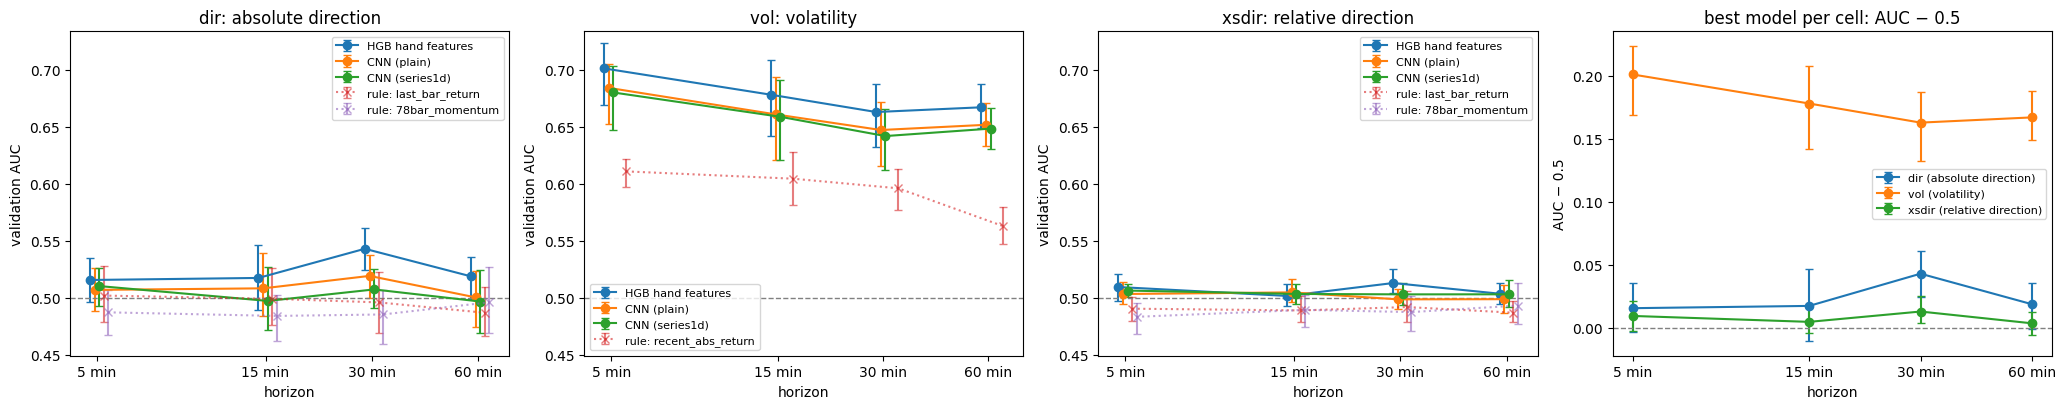

- **dir (absolute direction)**: best AUC by horizon 5 min 0.516 [0.496, 0.535] (HGB hand features), 15 min 0.517 [0.490, 0.546] (HGB hand features), 30 min 0.543 [0.525, 0.561] (HGB hand features), 60 min 0.519 [0.499, 0.536] (HGB hand features). 95% CI above 0.5 at 30 min.
- **vol (volatility)**: best AUC by horizon 5 min 0.701 [0.669, 0.724] (HGB hand features), 15 min 0.678 [0.642, 0.708] (HGB hand features), 30 min 0.663 [0.632, 0.687] (HGB hand features), 60 min 0.667 [0.649, 0.688] (HGB hand features). 95% CI above 0.5 at 5 min, 15 min, 30 min, 60 min.
- **xsdir (relative direction)**: best AUC by horizon 5 min 0.509 [0.497, 0.521] (HGB hand features), 15 min 0.505 [0.496, 0.516] (CNN (plain)), 30 min 0.513 [0.504, 0.525] (HGB hand features), 60 min 0.504 [0.495, 0.513] (HGB hand features). 95% CI above 0.5 at 30 min.
- dir decile long-short (top − bottom, gross, bps per horizon): dir_h1 HGB hand features +3.50 bps (t = 2.14)
- xsdir decile long-short (top − bottom, gross, bps per horizon): xsdir_h6 CNN (series1d) +3.94 bps (t = 2.03)
- image CNN − 1D CNN AUC (paired day bootstrap) across 12 cells: better in 2, worse in 0, tied in 10.
- image CNN − HGB AUC (paired day bootstrap) across 12 cells: better in 0, worse in 5, tied in 7.

saved to /content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/Multi-Target Chart CNN Baseline/runs/run_20261114_223246


In [ ]:
grid.plot_grid(TABLE, RUN_LOCAL / "auc_by_horizon.png")
TAKEAWAYS = grid.takeaways(TABLE, BOOTS)
(RUN_LOCAL / "takeaways.md").write_text(TAKEAWAYS + "\n"); display(Markdown(TAKEAWAYS))
for name in ("labels.csv", "grid_table.csv", "auc_by_horizon.png", "takeaways.md"):
    shutil.copy2(RUN_LOCAL / name, RUN_DRIVE / name)
print("saved to", RUN_DRIVE)